Here we look into the metadata and try to analyze induviduals and different cells the samples are from

In [1]:
import pandas as pd

In [2]:
samples_df = pd.read_csv(r'..\data\sample_metadata.tsv', sep='\t')
individuals_df = pd.read_csv(r'..\data\individual_metadata.tsv', sep='\t')
samples_to_individuals_df = pd.read_csv(r'..\data\sample_individual_mapping.tsv', sep='\t')


In [3]:
samples_df.head()

,sanger_sample_id,biopsy_type,bead_version,bead_lot,chip_version,chip_lot,enzyme_lot_BLP,gem_lot,f2_f1_ratio
0,5892STDY10205765,terminal ileum,V3.1,NaN,chip-g,lot_160047,SLCB6672,lot_155287,04:01:00
1,5892STDY10315937,terminal ileum,V3.1,lot_160848,chip-g,lot_160047,SLCD4967,lot_160900,01:00:00
2,5892STDY10315938,terminal ileum,V3.1,lot_160848,chip-g,lot_160047,SLCD4967,lot_160900,01:00:00
3,5892STDY10653007,terminal ileum,V3.1,lot_160848,chip-g,lot_160047,SLCD4967,lot_160900,04:01:00
4,5892STDY10653009,terminal ileum,V3.1,lot_160848,chip-g,lot_160673,SLCD4967,lot_160851,01:00:00


In [4]:
samples_df.shape

(343, 9)

In [5]:
samples_df['biopsy_type'].value_counts()

biopsy_type
terminal ileum    343
Name: count, dtype: int64

In [6]:
individuals_df.head()

,individual_id,disease_status,age_binned_10,sex,ti_ses_inflamed
0,IBDverse-1-3A5C2FF82FA8A4,CD,40,male,inflamed
1,IBDverse-1-0DD5B680D0BFFB,CD,60,male,inflamed
2,IBDverse-1-B257F708E64F29,CD,30,female,inflamed
3,IBDverse-1-8D29C5BD7C12C7,CD,40,female,inflamed
4,IBDverse-1-B45A577AF0E969,CD,30,female,inflamed


In [7]:
individuals_df.shape

(343, 5)

In [8]:
individuals_df['disease_status'].value_counts()

disease_status
Healthy    232
CD         111
Name: count, dtype: int64

<Axes: title={'center': 'Number of individuals by age group'}, xlabel='age_binned_10'>

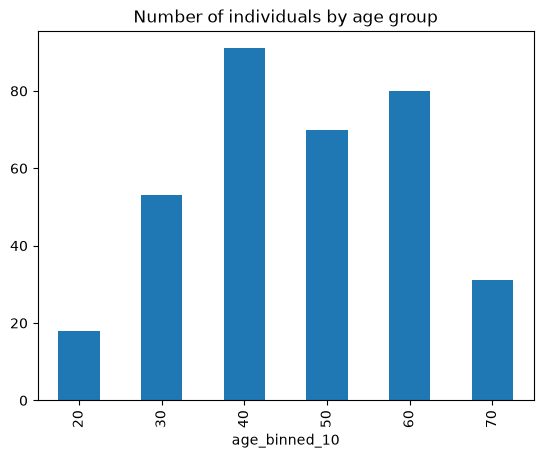

In [9]:
individuals_df['age_binned_10'].value_counts().sort_index().plot(kind='bar', title='Number of individuals by age group')

In [10]:
individuals_df['sex'].value_counts()

sex
female    177
male      166
Name: count, dtype: int64

In [11]:
individuals_df.groupby('disease_status')['ti_ses_inflamed'].value_counts()

disease_status  ti_ses_inflamed
CD              inflamed            64
                uninflamed          47
Healthy         uninflamed         232
Name: count, dtype: int64

In [12]:
individuals_df[individuals_df['disease_status'] == 'CD'].groupby('ti_ses_inflamed')['sex'].value_counts()

ti_ses_inflamed  sex   
inflamed         female    33
                 male      31
uninflamed       female    30
                 male      17
Name: count, dtype: int64

In [13]:
individuals_df.groupby('disease_status')['sex'].value_counts()

disease_status  sex   
CD              female     63
                male       48
Healthy         male      118
                female    114
Name: count, dtype: int64

In [14]:
individuals_df.groupby('disease_status')['age_binned_10'].agg(['count', 'mean', 'min', 'max', 'median'])

,count,mean,min,max,median
disease_status,,,,,
CD,111,41.621622,20,70,40.0
Healthy,232,49.310345,20,70,50.0


In [15]:
samples_to_individuals_df.head()

,individual_id,sanger_sample_id
0,IBDverse-1-3A5C2FF82FA8A4,5892STDY10205765
1,IBDverse-1-0DD5B680D0BFFB,5892STDY10315937
2,IBDverse-1-B257F708E64F29,5892STDY10315938
3,IBDverse-1-8D29C5BD7C12C7,5892STDY10653007
4,IBDverse-1-B45A577AF0E969,5892STDY10653009


In [16]:
samples_to_individuals_df.shape

(732, 2)

Check if the samples-to individual file contains all samples, and individual from samples_df and individuals_df

In [17]:
sample_match_count = (samples_df['sanger_sample_id'].isin(samples_to_individuals_df['sanger_sample_id'])).sum()
Missing_sample_count = (~samples_df['sanger_sample_id'].isin(samples_to_individuals_df['sanger_sample_id'])).sum()

individual_match_count = (individuals_df['individual_id'].isin(samples_to_individuals_df['individual_id'])).sum()
missing_individual_count = (~individuals_df['individual_id'].isin(samples_to_individuals_df['individual_id'])).sum()

print(f"matching samples: {sample_match_count}")
print(f"matching individuals: {individual_match_count}")

print(f"Number of samples in sample metadata that do not have a match in the mapping file: {Missing_sample_count}")
print(f"Number of individuals in individual metadata that do not have a match in the mapping file: {missing_individual_count}")

matching samples: 342
matching individuals: 342
Number of samples in sample metadata that do not have a match in the mapping file: 1
Number of individuals in individual metadata that do not have a match in the mapping file: 1


In [18]:
# find what samples are missing in the mapping file
missing_samples = samples_df[~samples_df['sanger_sample_id'].isin(samples_to_individuals_df['sanger_sample_id'])]
missing_samples

,sanger_sample_id,biopsy_type,bead_version,bead_lot,chip_version,chip_lot,enzyme_lot_BLP,gem_lot,f2_f1_ratio
92,5892STDY8357646,terminal ileum,V3,lot_154306,chip-b,lot_153745,SLBZ4589,lot_154140,01:00:00


In [19]:
# find what individuals are missing in the mapping file
missing_individuals = individuals_df[~individuals_df['individual_id'].isin(samples_to_individuals_df['individual_id'])]
missing_individuals

,individual_id,disease_status,age_binned_10,sex,ti_ses_inflamed
92,IBDverse-1-4C853150C0F68D,CD,40,male,inflamed


In [20]:
samples_to_individuals_df.loc[samples_to_individuals_df['sanger_sample_id'] == missing_samples.iloc[0]['sanger_sample_id']]

,individual_id,sanger_sample_id


In [21]:
samples_to_individuals_df.loc[samples_to_individuals_df['individual_id'] == missing_individuals.iloc[0]['individual_id']]

,individual_id,sanger_sample_id


In [22]:
temp_mapping = pd.merge(samples_df, samples_to_individuals_df, on='sanger_sample_id', how='left')
mapping_df = pd.merge(temp_mapping, individuals_df, on='individual_id', how='left')

In [23]:
mapping_df.shape

(343, 14)

In [24]:
mapping_df.head()

,sanger_sample_id,biopsy_type,bead_version,bead_lot,chip_version,chip_lot,enzyme_lot_BLP,gem_lot,f2_f1_ratio,individual_id,disease_status,age_binned_10,sex,ti_ses_inflamed
0,5892STDY10205765,terminal ileum,V3.1,NaN,chip-g,lot_160047,SLCB6672,lot_155287,04:01:00,IBDverse-1-3A5C2FF82FA8A4,CD,40.0,male,inflamed
1,5892STDY10315937,terminal ileum,V3.1,lot_160848,chip-g,lot_160047,SLCD4967,lot_160900,01:00:00,IBDverse-1-0DD5B680D0BFFB,CD,60.0,male,inflamed
2,5892STDY10315938,terminal ileum,V3.1,lot_160848,chip-g,lot_160047,SLCD4967,lot_160900,01:00:00,IBDverse-1-B257F708E64F29,CD,30.0,female,inflamed
3,5892STDY10653007,terminal ileum,V3.1,lot_160848,chip-g,lot_160047,SLCD4967,lot_160900,04:01:00,IBDverse-1-8D29C5BD7C12C7,CD,40.0,female,inflamed
4,5892STDY10653009,terminal ileum,V3.1,lot_160848,chip-g,lot_160673,SLCD4967,lot_160851,01:00:00,IBDverse-1-B45A577AF0E969,CD,30.0,female,inflamed


In [25]:
mapping_df[mapping_df['individual_id'].isnull()]

,sanger_sample_id,biopsy_type,bead_version,bead_lot,chip_version,chip_lot,enzyme_lot_BLP,gem_lot,f2_f1_ratio,individual_id,disease_status,age_binned_10,sex,ti_ses_inflamed
92,5892STDY8357646,terminal ileum,V3,lot_154306,chip-b,lot_153745,SLBZ4589,lot_154140,01:00:00,NaN,NaN,NaN,NaN,NaN


In [26]:
mapping_df.groupby('biopsy_type')['disease_status'].value_counts()

biopsy_type     disease_status
terminal ileum  Healthy           232
                CD                110
Name: count, dtype: int64

In [27]:
individuals_df.groupby(['disease_status', 'ti_ses_inflamed'])['age_binned_10'].describe()

count       mean        std   min   25%   50%  \
disease_status ti_ses_inflamed                                                  
CD             inflamed          64.0  39.687500  10.384474  20.0  30.0  40.0   
               uninflamed        47.0  44.255319  13.632551  20.0  35.0  40.0   
Healthy        uninflamed       232.0  49.310345  13.657793  20.0  40.0  50.0   

                                 75%   max  
disease_status ti_ses_inflamed              
CD             inflamed         40.0  60.0  
               uninflamed       50.0  70.0  
Healthy        uninflamed       60.0  70.0

In [28]:
mapping_df.groupby(['disease_status', 'ti_ses_inflamed'])['age_binned_10'].describe()

count       mean        std   min   25%   50%  \
disease_status ti_ses_inflamed                                                  
CD             inflamed          63.0  39.682540  10.467808  20.0  30.0  40.0   
               uninflamed        47.0  44.255319  13.632551  20.0  35.0  40.0   
Healthy        uninflamed       232.0  49.310345  13.657793  20.0  40.0  50.0   

                                 75%   max  
disease_status ti_ses_inflamed              
CD             inflamed         40.0  60.0  
               uninflamed       50.0  70.0  
Healthy        uninflamed       60.0  70.0

<Axes: title={'center': 'Age distribution by disease status and inflammation status'}, xlabel='disease_status,ti_ses_inflamed,age_binned_10'>

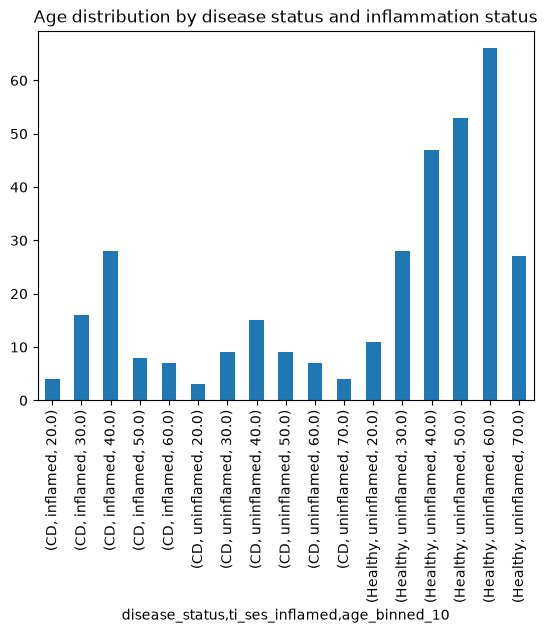

In [29]:
mapping_df.groupby(['disease_status', 'ti_ses_inflamed'])['age_binned_10'].value_counts().sort_index().plot(kind='bar', title='Age distribution by disease status and inflammation status')

In [30]:
mapping_df.to_csv(r'..\data\mapped_data.tsv', sep='\t', index=None)

In [31]:
mapping_df.notna().sum()

sanger_sample_id    343
biopsy_type         343
bead_version        339
bead_lot            333
chip_version        337
chip_lot            329
enzyme_lot_BLP      339
gem_lot             336
f2_f1_ratio          69
individual_id       342
disease_status      342
age_binned_10       342
sex                 342
ti_ses_inflamed     342
dtype: int64

In [35]:
samples_df.isna().sum()

sanger_sample_id      0
biopsy_type           0
bead_version          4
bead_lot             10
chip_version          6
chip_lot             14
enzyme_lot_BLP        4
gem_lot               7
f2_f1_ratio         274
dtype: int64

In [33]:
individuals_df.notna().sum()

individual_id      343
disease_status     343
age_binned_10      343
sex                343
ti_ses_inflamed    343
dtype: int64